<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-071-barren-plateaus.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 071. Barren plateaus

A variational circuit is trained by following the gradient of its cost, and on a device every gradient component is estimated from a finite number of shots. The component is useful only when it is larger than the shot noise of its estimate. We test whether the gradient stays large enough to be measured as the number of qubits $N$ grows. The angles of the circuit are drawn at random, as at the start of a training run, and for each draw we compute one gradient component exactly. The spread of this component over many draws is its typical size.

We are given two circuit families, the hardware-efficient ansatz (HEA) and the Hamiltonian-variational ansatz (HVA) for the transverse-field Ising chain, and three cost functions, a global cost, a local cost and the energy of the chain. We compute the variance of one gradient component over 300 random angle vectors for $N=2,4,6,8,10$, its decay with $N$, and the number of shots needed to resolve a typical gradient on a device. For deep random circuits and for global costs the variance decays exponentially with $N$, and the training landscape becomes flat almost everywhere. Such a flat landscape is called a barren plateau [1].

Section 2 builds the simulator, the two circuit families and the three costs. Section 3 defines the gradient statistics, and Section 4 explains why expectation values in random states concentrate around their mean. Section 5 measures the gradient variance of the HEA with a global and a local cost, Section 6 that of the energy for the HEA and the HVA, and Section 7 converts the variances into numbers of shots. Sections 1 to 7 form the core route. Section 8, for reading at home, describes plateaus caused by noise and the known ways of avoiding plateaus.

All gradients are exact, computed from the state vector with automatic differentiation. Only the shot counts of Section 7 refer to what a device would measure.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`. JAX applies the gates, differentiates the costs with `jax.grad` and its two-output version `jax.jacrev`, evaluates many random draws at once with `jax.vmap`, and draws the random numbers on the CPU. The cells run in order.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"   # small calculations; the CPU avoids GPU memory allocation
import json, time
from pathlib import Path
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
CDTYPE = jnp.complex128
TOL = 1e-12
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 10, "figure.figsize": (4.8, 3.2), "savefig.bbox": "tight"})
# course palette: HEA blue, HVA orange, exact black, mean field grey (dashed), random baseline light grey
COL = dict(hea="#005CA7", hva="#D35A05", spa="#1B7F36", exact="black", mf="#5A6270", rand="#9AA0A6",
           data="#3E8FD0", navy="#002B5C")
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})   # TrueType fonts: the PDFs embed cleanly in LaTeX
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
started = time.perf_counter()
NUMBERS = {}
def sci(x, digits=1):
    # LaTeX form of a number in scientific notation for the macro file, e.g. 1.1\times10^{5} (used in math mode)
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
N_LIST = (2, 4, 6, 8, 10)
R_DRAWS = 300            # random angle vectors per point
J, h = 1.0, 1.0          # TFIM couplings, critical point
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. Circuits and costs

The state of $N$ qubits is a tensor $\psi[b_0,\dots,b_{N-1}]$ with one index per qubit, and a single-qubit gate contracts its matrix with one index. A rotation about a Pauli matrix $\hat P$ is $\hat R_P(\theta)=e^{-i\theta\hat P/2}=\cos(\theta/2)\hat I-i\sin(\theta/2)\hat P$. A layer of single-qubit gates acts on every qubit, and the code applies it in a loop that rotates the first index of the tensor and then moves this index to the last position. After $N$ such steps every qubit has received its gate and the indices are back in their original order. The loop body is the same at every step, so `jax.lax.scan` compiles it once, which keeps the compilation short for the many circuits of this notebook. The code checks the loop against gates applied one qubit at a time.

The hardware-efficient ansatz starts in $|0\dots0\rangle$ and has $L$ layers. Each layer applies $\hat R_y$ and then $\hat R_z$ with independent angles to every qubit and then a chain of controlled-$\hat Z$ gates on the neighbouring pairs $(q,q+1)$. A final rotation block ends the circuit, so there are $n=2N(L+1)$ angles [2]. The $\widehat{\mathrm{CZ}}$ chain multiplies the amplitude of each bit string $\mathbf b$ by $(-1)^{\sum_qb_qb_{q+1}}$. The angle $\theta_1$ that we differentiate is the $\hat R_y$ angle of qubit 0 in the first block.

The Hamiltonian-variational ansatz is built from the two parts of the Ising Hamiltonian
$$\hat{\mathcal H}=-J\sum_{i=0}^{N-2}\hat Z_i\hat Z_{i+1}-h\sum_{i=0}^{N-1}\hat X_i , \tag{1}$$
which we use at the critical point $J=h=1$ [3,4]. It starts in $|{+}\dots{+}\rangle$, the ground state of $-h\sum_i\hat X_i$, and applies $L$ layers
$$\hat U_\ell=e^{-i\beta_\ell\sum_i\hat X_i}\,e^{-i\gamma_\ell\sum_i\hat Z_i\hat Z_{i+1}} , \tag{2}$$
with $n=2L$ angles, stored layer by layer as $(\gamma_1,\beta_1,\gamma_2,\beta_2,\dots,\gamma_L,\beta_L)$. The first factor is a product of $\hat R_x(2\beta_\ell)$ on every qubit, and the second a product of $\hat R_{zz}(2\gamma_\ell)$ on every bond, which multiplies the amplitude of $\mathbf b$ by the phase $e^{-i\gamma_\ell\sum_iz_iz_{i+1}}$ with $z_i=(-1)^{b_i}$. Each angle is shared by all qubits or all bonds of its layer. Both factors commute with the parity $\hat\Pi=\prod_i\hat X_i$, and the state stays in the sector $\hat\Pi=+1$ of $|{+}\dots{+}\rangle$. The angle we differentiate is $\gamma_1$.

The three cost functions are
$$C_G(\boldsymbol\theta)=1-|\langle0\dots0|\psi(\boldsymbol\theta)\rangle|^2,\qquad C_L(\boldsymbol\theta)=\frac1N\sum_{q=0}^{N-1}\frac{1-\langle\hat Z_q\rangle}{2},\qquad E(\boldsymbol\theta)=\langle\psi(\boldsymbol\theta)|\hat{\mathcal H}|\psi(\boldsymbol\theta)\rangle . \tag{3}$$
The global cost $C_G$ is the probability that a measured bit string differs from $0\dots0$, and it depends on all qubits together. The local cost $C_L$ is the probability that a single qubit, averaged over the qubits, reads 1. Both costs vanish only in the state $|0\dots0\rangle$, so they have the same minimum, and $C_L$ is a sum of single-qubit terms. The energy is a sum of $2N-1$ terms acting on one or two neighbouring qubits, so it is also a local cost. The function `energy_and_variance` returns, besides $E$, the single-shot variance $\sigma^2=\sigma_Z^2+\sigma_X^2$ of an energy measurement in the two settings (all qubits in $z$, all qubits in $x$), which Section 7 needs.

In [2]:
I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
Y = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
HAD = (X + Z) / jnp.sqrt(2.0)

def rotation(P, theta):
    return jnp.cos(theta / 2) * I2 - 1j * jnp.sin(theta / 2) * P

def apply_1q(psi, U, q):
    return jnp.moveaxis(jnp.tensordot(U, psi, axes=([1], [q])), 0, q)

def rotate_all(psi, Us):
    # Us[q] acts on qubit q: rotate index 0, move it to the end, repeat N times
    def step(p, U):
        return jnp.moveaxis(jnp.tensordot(U, p, axes=([1], [0])), 0, -1), None
    return jax.lax.scan(step, psi, Us)[0]

def tables(N):
    # z[q] = (-1)^{b_q}, zz = sum_i z_i z_{i+1}, cz = (-1)^{sum_q b_q b_{q+1}} on every basis state
    b = np.indices((2,) * N)
    z = (-1.0) ** b
    zz = sum(z[i] * z[i + 1] for i in range(N - 1))
    cz = (-1.0) ** sum(b[i] * b[i + 1] for i in range(N - 1))
    return jnp.asarray(z), jnp.asarray(zz), jnp.asarray(cz)

def ry_rz(angles):
    # angles[q] = (R_y angle, R_z angle); R_y acts first
    return jax.vmap(lambda a: rotation(Z, a[1]) @ rotation(Y, a[0]))(angles)

def hea_state(theta, N, L):
    _, _, cz = tables(N)
    th = theta.reshape(L + 1, N, 2)
    psi = jnp.zeros((2,) * N, dtype=CDTYPE).at[(0,) * N].set(1.0)
    psi, _ = jax.lax.scan(lambda p, a: (rotate_all(p, ry_rz(a)) * cz, None), psi, th[:L])
    return rotate_all(psi, ry_rz(th[L]))

def hva_state(theta, N, L):
    _, zz, _ = tables(N)
    psi = jnp.ones((2,) * N, dtype=CDTYPE) / 2 ** (N / 2)          # |+...+>
    def layer(p, gb):
        gamma, beta = gb
        p = p * jnp.exp(-1j * gamma * zz)                            # exp(-i gamma sum Z_i Z_{i+1})
        return rotate_all(p, jnp.broadcast_to(rotation(X, 2 * beta), (N, 2, 2))), None   # exp(-i beta sum X_i)
    psi, _ = jax.lax.scan(layer, psi, theta.reshape(L, 2))          # rows (gamma_l, beta_l)
    return psi

def cost_global(psi):
    return 1.0 - jnp.abs(psi.reshape(-1)[0]) ** 2

def cost_local(psi):
    z, _, _ = tables(psi.ndim)
    p = jnp.abs(psi) ** 2
    return jnp.mean((1.0 - jnp.sum(p * z, axis=tuple(range(1, psi.ndim + 1)))) / 2)

def energy_and_variance(psi):
    N = psi.ndim
    z, zz, _ = tables(N)
    eZ, eX = -J * zz, -h * z.sum(axis=0)                            # single-shot values of the two settings
    pz = jnp.abs(psi) ** 2
    px = jnp.abs(rotate_all(psi, jnp.broadcast_to(HAD, (N, 2, 2)))) ** 2
    E = jnp.sum(pz * eZ) + jnp.sum(px * eX)
    var = jnp.sum(pz * eZ ** 2) - jnp.sum(pz * eZ) ** 2 + jnp.sum(px * eX ** 2) - jnp.sum(px * eX) ** 2
    return E, var

# checks on N = 4
N4, L4 = 4, 3
th = jax.random.uniform(jax.random.PRNGKey(7101), (2 * N4 * (L4 + 1),), minval=-np.pi, maxval=np.pi)
psi_loop = jnp.zeros((2,) * N4, dtype=CDTYPE).at[(0,) * N4].set(1.0)
for l, a in enumerate(th.reshape(L4 + 1, N4, 2)):
    for q in range(N4):
        psi_loop = apply_1q(psi_loop, rotation(Z, a[q, 1]) @ rotation(Y, a[q, 0]), q)
    if l < L4:
        psi_loop = psi_loop * tables(N4)[2]
assert jnp.allclose(psi_loop, hea_state(th, N4, L4), atol=TOL)
psi_h = hva_state(th[:6], N4, 3)
assert abs(jnp.linalg.norm(psi_h) - 1) < TOL
parity = jnp.vdot(psi_h, jnp.flip(psi_h)).real                       # prod_i X_i flips every bit
assert abs(parity - 1) < TOL
H_dense = sum(-J * jnp.kron(jnp.kron(jnp.eye(2 ** i), jnp.kron(Z, Z)), jnp.eye(2 ** (N4 - i - 2))) for i in range(N4 - 1)) \
        + sum(-h * jnp.kron(jnp.kron(jnp.eye(2 ** i), X), jnp.eye(2 ** (N4 - i - 1))) for i in range(N4))
v = psi_h.reshape(-1)
assert abs(energy_and_variance(psi_h)[0] - jnp.vdot(v, H_dense @ v).real) < TOL
zero = jnp.zeros(2 * N4 * (L4 + 1))
assert abs(cost_global(hea_state(zero, N4, L4))) < TOL and abs(cost_local(hea_state(zero, N4, L4))) < TOL
print("scan over qubits = gate-by-gate circuit; HVA keeps parity +1; energy matches the dense Hamiltonian; C_G = C_L = 0 on |0...0>")

scan over qubits = gate-by-gate circuit; HVA keeps parity +1; energy matches the dense Hamiltonian; C_G = C_L = 0 on |0...0>


## 3. Gradient statistics over random angles

At the start of a training run the angles are often drawn uniformly from $[-\pi,\pi]$. We draw $R=300$ such angle vectors $\boldsymbol\theta^{(1)},\dots,\boldsymbol\theta^{(R)}$ and compute the derivative $\partial_kC=\partial C/\partial\theta_k$ of a cost $C$ at each of them, where $\theta_k$ is the angle chosen in Section 2. Along a single angle every cost of this notebook has the form $a+b\cos(\theta_k-c)$, because each rotation is generated by Pauli strings with eigenvalues $\pm1$, and the constants $a$, $b$, $c$ depend on the other angles. The derivative $-b\sin(\theta_k-c)$ averages to zero over $\theta_k$ for any values of the other angles, so the mean gradient over random angles vanishes for every circuit. The typical size of a gradient component is therefore measured by its variance,
$$\mathrm{Var}_{\boldsymbol\theta}[\partial_kC]=\big\langle(\partial_kC)^2\big\rangle_{\boldsymbol\theta} , \tag{4}$$
where $\langle\cdot\rangle_{\boldsymbol\theta}$ is the average over the uniform distribution of the angles, and $\sqrt{\mathrm{Var}_{\boldsymbol\theta}[\partial_kC]}$ is the size of a typical component. We estimate it by the sample variance $\tilde V$ of the $R$ values. The distribution of $\partial_kC$ can have long tails, so its standard error is computed from the fourth central moment $\tilde\mu_4$ of the sample, $\sigma_{\tilde V}=\sqrt{(\tilde\mu_4-\tilde V^2)/R}$, which holds for any distribution. The sketch contrasts a landscape with large gradients and a barren plateau, flat within the shot noise except near the minimum.

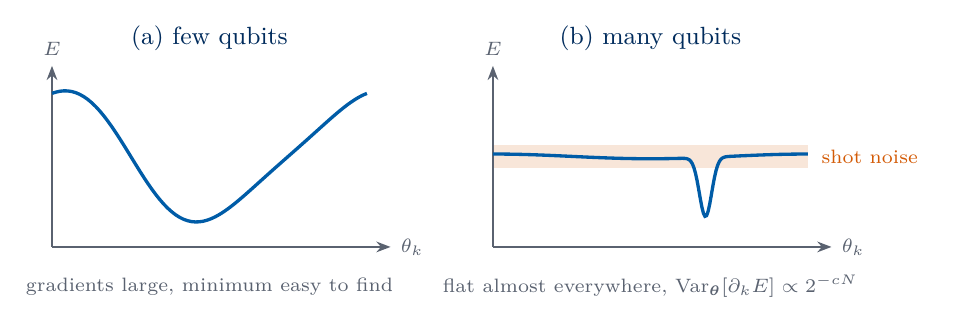

*Energy along one angle for few qubits, with large gradients, and for many qubits, flat almost everywhere within the shot noise.*

All $R$ gradients are computed in one call. `jax.grad` turns the cost into its gradient function, `jax.vmap` evaluates it for all draws at once, and `jax.jit` compiles the result. When two costs are evaluated on the same circuit, `jax.jacrev` returns both gradients, one per row, from a single run of the circuit.

In [3]:
def var_with_error(g):
    d = g - g.mean()
    v = float(np.mean(d ** 2))
    return v, float(np.sqrt((np.mean(d ** 4) - v ** 2) / g.size))

def random_angles(seed, n):
    return jax.random.uniform(jax.random.PRNGKey(seed), (R_DRAWS, n), minval=-np.pi, maxval=np.pi)

def batched_gradients(cost_vector, thetas):
    # cost_vector(theta) -> (vector of costs, auxiliary output); returns the gradients of all costs at all draws
    return jax.jit(jax.vmap(jax.jacrev(cost_vector, has_aux=True)))(thetas)

# the mean-zero argument on one example: the HEA, N = 4, L = 2, global cost
g_demo, _ = batched_gradients(lambda t: (jnp.stack([cost_global(hea_state(t, 4, 2))]), 0.0), random_angles(1, 2 * 4 * 3))
g_demo = np.asarray(g_demo[:, 0, 0])
v_demo, se_demo = var_with_error(g_demo)
print(f"HEA N=4, L=2, global cost: mean of d C_G / d theta_1 = {g_demo.mean():+.4f} +- {g_demo.std() / np.sqrt(R_DRAWS):.4f}, "
      f"variance {v_demo:.2e} +- {se_demo:.0e}")

HEA N=4, L=2, global cost: mean of d C_G / d theta_1 = -0.0041 +- 0.0032, variance 3.11e-03 +- 4e-04


## 4. Concentration in random states

A circuit with many layers of randomly chosen gates behaves, for averages of expectation values and of their squares, like a unitary drawn uniformly from all unitaries on the $d=2^N$-dimensional state space. The uniform distribution over unitaries is called the Haar distribution, and a set of circuits that reproduces its averages of first and second order is a unitary 2-design [1]. A random unitary applied to $|0\dots0\rangle$ gives a random state, whose $d$ amplitudes are, up to normalisation, independent complex Gaussian numbers.

In a random state every expectation value is close to its average over all states. For a Pauli string $\hat P\neq\hat I$ the average of $\langle\hat P\rangle$ vanishes and its variance is
$$\mathrm{Var}\,\langle\hat P\rangle=\frac1{d+1}\approx2^{-N} . \tag{5}$$
For $\hat Z_0$ this follows directly, since $\langle\hat Z_0\rangle$ is the total probability of the bit strings with $b_0=0$ minus that of the strings with $b_0=1$, two sums of $d/2$ random weights that each fluctuate by about $2^{-N/2}$ around one half. Two random states are also nearly orthogonal, $\langle|\langle0\dots0|\psi\rangle|^2\rangle=1/d$, so the probability of any fixed bit string is of order $2^{-N}$, with fluctuations of the same order.

The gradient inherits this concentration. Let the differentiated rotation act on $|0\dots0\rangle$ first and let a Haar-random unitary $\hat W$ represent all the gates after it. A cost $C=\langle\hat O\rangle$ with a Hermitian observable $\hat O$ then has the gradient variance
$$\mathrm{Var}_{\boldsymbol\theta}[\partial_kC]=\frac{\mathrm{Tr}(\hat O_0^2)}{2(d^2-1)} , \tag{6}$$
where $\hat O_0=\hat O-\mathrm{Tr}(\hat O)\hat I/d$ is the traceless part of $\hat O$. Equation (6) follows from the Haar average $\langle\mathrm{Tr}(\hat W^\dagger\hat A\hat W\hat B)^2\rangle_{\hat W}=\mathrm{Tr}(\hat A^2)\,\mathrm{Tr}(\hat B^2)/(d^2-1)$, valid for traceless Hermitian $\hat A$ and $\hat B$, with $\hat A=\hat O_0$ and $\hat B$ the traceless operator produced by differentiating the rotation, for which $\mathrm{Tr}(\hat B^2)=1/2$. The size $\mathrm{Tr}(\hat O_0^2)$ decides the decay. The global cost has $\hat O=\hat I-|0\dots0\rangle\langle0\dots0|$, with $\mathrm{Tr}(\hat O_0^2)=1-1/d$, and its variance $1/[2d(d+1)]\approx2^{-2N-1}$ decays as $4^{-N}$. A sum of Pauli strings $\sum_jc_j\hat P_j$ has $\mathrm{Tr}(\hat O_0^2)=d\sum_jc_j^2$, so the energy (1) has $\mathrm{Var}\approx[(N-1)J^2+Nh^2]/2^{N+1}$ and the local cost has $\mathrm{Var}\approx2^{-N}/(8N)$. For a circuit that acts as a 2-design every cost decays exponentially with $N$, the global one twice as fast.

The code samples 2000 random states for each $N$ and compares the variance of $\langle\hat Z_0\rangle$ and the mean of $|\langle0\dots0|\psi\rangle|^2$ with equation (5). It then checks equation (6) for the three costs with $\hat R_y(\theta_1)$ on qubit 0 followed by Haar-random unitaries on $N=2,4,6$ qubits.

N: [2, 4, 6, 8, 10]
Var <Z_0> x (d+1):         [0.973, 1.015, 0.959, 1.031, 1.018]
mean |<0..0|psi>|^2 x d:   [1.03, 0.974, 0.985, 0.991, 0.976]
N=2 global: Haar-random circuits 2.538e-02 +- 8e-04, equation (6) 2.500e-02
N=2 local : Haar-random circuits 1.689e-02 +- 5e-04, equation (6) 1.667e-02
N=2 energy: Haar-random circuits 4.117e-01 +- 1e-02, equation (6) 4.000e-01
N=4 global: Haar-random circuits 1.846e-03 +- 7e-05, equation (6) 1.838e-03
N=4 local : Haar-random circuits 1.864e-03 +- 6e-05, equation (6) 1.961e-03
N=4 energy: Haar-random circuits 2.099e-01 +- 7e-03, equation (6) 2.196e-01
N=6 global: Haar-random circuits 1.177e-04 +- 5e-06, equation (6) 1.202e-04
N=6 local : Haar-random circuits 3.238e-04 +- 1e-05, equation (6) 3.256e-04
N=6 energy: Haar-random circuits 8.985e-02 +- 3e-03, equation (6) 8.596e-02


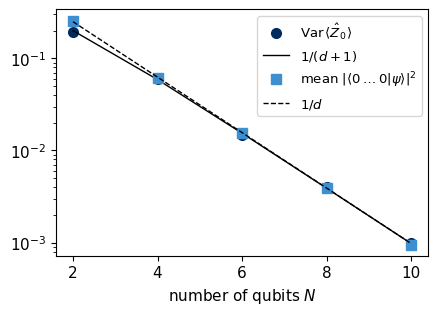

In [4]:
def random_states(key, N, count):
    k1, k2 = jax.random.split(key)
    v = jax.random.normal(k1, (count, 2 ** N)) + 1j * jax.random.normal(k2, (count, 2 ** N))
    return v / jnp.linalg.norm(v, axis=1, keepdims=True)

def haar_unitary(key, d):
    # QR decomposition of a complex Gaussian matrix, with the phases of R moved into Q
    k1, k2 = jax.random.split(key)
    A = (jax.random.normal(k1, (d, d)) + 1j * jax.random.normal(k2, (d, d))) / np.sqrt(2)
    Q, Rm = jnp.linalg.qr(A)
    return Q * (jnp.diag(Rm) / jnp.abs(jnp.diag(Rm)))[None, :]

rs_var_z, rs_mean_ov = [], []
for N in N_LIST:
    s = random_states(jax.random.PRNGKey(7100 + N), N, 2000)
    sign0 = jnp.where(jnp.arange(2 ** N) < 2 ** (N - 1), 1.0, -1.0)      # (-1)^{b_0}
    z0 = np.asarray(jnp.sum(jnp.abs(s) ** 2 * sign0, axis=1))
    rs_var_z.append(z0.var()); rs_mean_ov.append(float(jnp.mean(jnp.abs(s[:, 0]) ** 2)))
    d = 2 ** N
    assert abs(z0.var() * (d + 1) - 1) < 0.15 and abs(rs_mean_ov[-1] * d - 1) < 0.15
print("N:", list(N_LIST))
print("Var <Z_0> x (d+1):        ", np.round(np.array(rs_var_z) * (2 ** np.array(N_LIST) + 1), 3).tolist())
print("mean |<0..0|psi>|^2 x d:  ", np.round(np.array(rs_mean_ov) * 2 ** np.array(N_LIST), 3).tolist())

def haar_formula(N, cost):
    d = 2.0 ** N
    tr = {"global": 1 - 1 / d, "local": d / (4 * N), "energy": d * ((N - 1) * J ** 2 + N * h ** 2)}[cost]
    return tr / (2 * (d * d - 1))                                       # equation (6)

haar_check = {}
for N in (2, 4, 6):
    def costs_after_haar(t, U):
        psi0 = jnp.zeros((2,) * N, dtype=CDTYPE).at[(0,) * N].set(1.0)
        psi = (U @ apply_1q(psi0, rotation(Y, t), 0).reshape(-1)).reshape((2,) * N)
        return jnp.stack([cost_global(psi), cost_local(psi), energy_and_variance(psi)[0]])
    keys = jax.random.split(jax.random.PRNGKey(7200 + N), 2000)
    Us = jax.vmap(lambda k: haar_unitary(k, 2 ** N))(keys)
    ts = jax.random.uniform(jax.random.PRNGKey(7300 + N), (2000,), minval=-np.pi, maxval=np.pi)
    G = np.asarray(jax.jit(jax.vmap(jax.jacfwd(costs_after_haar)))(ts, Us))
    for j, cost in enumerate(("global", "local", "energy")):
        v, se = var_with_error(G[:, j])
        haar_check[(N, cost)] = (v, se, haar_formula(N, cost))
        assert abs(v - haar_formula(N, cost)) < 4 * se
        print(f"N={N} {cost:6s}: Haar-random circuits {v:.3e} +- {se:.0e}, equation (6) {haar_formula(N, cost):.3e}")

fig, ax = plt.subplots()
Ns = np.array(N_LIST, dtype=float)
ax.semilogy(Ns, rs_var_z, "o", color=COL["navy"], ms=7, label=r"Var$\,\langle\hat Z_0\rangle$")
ax.semilogy(Ns, 1 / (2 ** Ns + 1), "-", color=COL["exact"], lw=1, label=r"$1/(d+1)$")
ax.semilogy(Ns, rs_mean_ov, "s", color=COL["data"], ms=7, label=r"mean $|\langle 0\dots0|\psi\rangle|^2$")
ax.semilogy(Ns, 1 / 2 ** Ns, "--", color=COL["exact"], lw=1, label=r"$1/d$")
ax.set_xlabel(r"number of qubits $N$"); ax.set_xticks(Ns); ax.legend(loc="upper right", fontsize=9.5)
save(fig, "fig_lab071_random_states"); plt.show()
NUMBERS.update(HaarVarZTen=sci(rs_var_z[-1]))

Both quantities fall on the lines $1/(d+1)$ and $1/d$, halving with every added qubit, and the gradient variances behind Haar-random unitaries agree with equation (6) within their statistical errors. A cost that is an expectation value in a nearly random state therefore carries almost no information about the angles.

## 5. Global and local costs of the hardware-efficient circuit

We measure $\mathrm{Var}_{\boldsymbol\theta}[\partial_1C]$ for the HEA in three cases, the global cost at depth $L=N$, the global cost at fixed depth $L=2$, and the local cost at $L=2$. At $N=2$ the two depths coincide. For each case we fit $\log_2\mathrm{Var}=\alpha-cN$ to the points $N=4$ to $10$, so that $\mathrm{Var}\propto2^{-cN}$, and compare with the 2-design value $1/[2d(d+1)]$ of the global cost, which corresponds to $c\approx2$.

For the local cost at fixed depth, the angle $\theta_1$ rotates qubit 0 in the first block, and each $\widehat{\mathrm{CZ}}$ layer passes its influence on by one qubit. After $L=2$ layers it reaches only qubits 0, 1 and 2, so only $\langle\hat Z_0\rangle$, $\langle\hat Z_1\rangle$ and $\langle\hat Z_2\rangle$ depend on $\theta_1$, and these three expectation values depend only on the angles of qubits 0 to 4. For $N\ge5$ the distribution of their derivative does not change with $N$, and the prefactor $1/N$ of $C_L$ in equation (3) gives
$$\mathrm{Var}_{\boldsymbol\theta}[\partial_1C_L]=\frac{\mathrm{const}}{N^2}\qquad(L=2,\ N\ge5) , \tag{7}$$
a power law in $N$. The code tests equation (7) through the products $N^2\,\mathrm{Var}$ at $N=6,8,10$. The sketch shows such a light cone for a brickwork circuit, which grows by one qubit per layer in the same way.

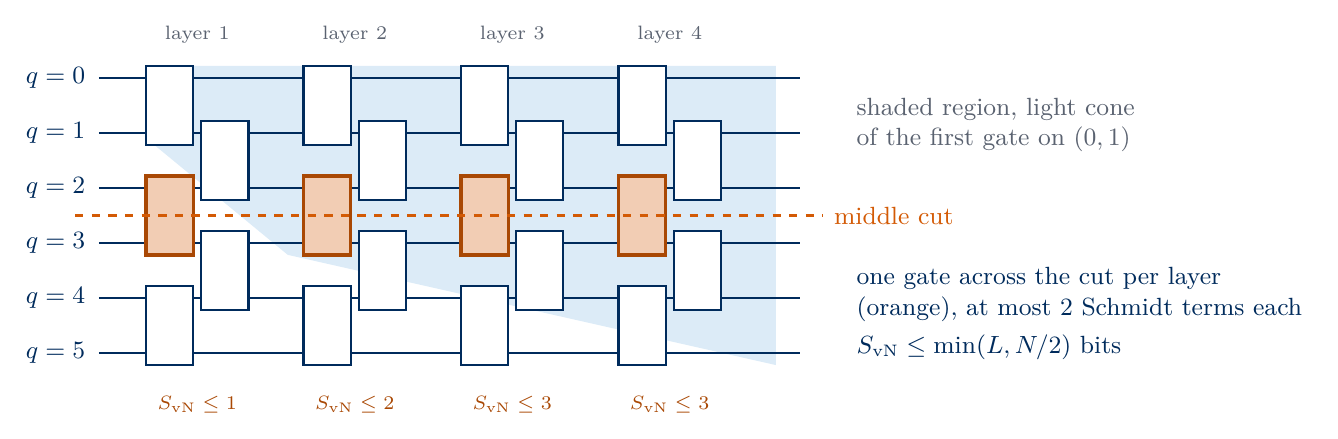

*Light cone of the first two-qubit gate in a brickwork circuit, growing by one qubit per layer, and the entanglement across the middle cut, which grows by at most one bit per layer.*

In [5]:
t_start = time.perf_counter()
CURVES = {}            # name -> list of (variance, standard error) over N_LIST
SIGMA2 = {}            # name -> mean single-shot variance of the energy at the sampled states
mean_over_sem = []
def record(name, g):
    CURVES.setdefault(name, []).append(var_with_error(np.asarray(g)))
    mean_over_sem.append(abs(np.mean(g)) / (np.std(g) / np.sqrt(g.size)))

for N in N_LIST:
    # HEA at depth L = N: global cost and energy from the same circuit
    def deep(t, N=N):
        psi = hea_state(t, N, N)
        E, var = energy_and_variance(psi)
        cg = cost_global(psi)
        return jnp.stack([cg, E]), (var, cg * (1 - cg))          # single shot of C_G is a yes-or-no outcome
    G, var = batched_gradients(deep, random_angles(10 + N, 2 * N * (N + 1)))
    record("HEA L=N, global", G[:, 0, 0]); record("HEA L=N, energy", G[:, 1, 0])
    SIGMA2.setdefault("HEA L=N, energy", []).append(float(np.mean(var[0])))
    SIGMA2.setdefault("HEA L=N, global", []).append(float(np.mean(var[1])))
    # HEA at depth L = 2: global and local cost from the same circuit
    def shallow(t, N=N):
        psi = hea_state(t, N, 2)
        p = jnp.abs(psi) ** 2
        ones = 0.5 - tables(N)[0].sum(axis=0) / (2 * N)        # single-shot value of C_L: fraction of bits equal to 1
        var_local = jnp.sum(p * ones ** 2) - jnp.sum(p * ones) ** 2
        return jnp.stack([cost_global(psi), cost_local(psi)]), var_local
    G, var = batched_gradients(shallow, random_angles(20 + N, 2 * N * 3))
    SIGMA2.setdefault("HEA L=2, local", []).append(float(np.mean(var)))
    record("HEA L=2, global", G[:, 0, 0]); record("HEA L=2, local", G[:, 1, 0])
    # HVA at depth L = N: energy, derivative with respect to gamma_1
    def hva(t, N=N):
        E, var = energy_and_variance(hva_state(t, N, N))
        return jnp.stack([E]), var
    G, var = batched_gradients(hva, random_angles(30 + N, 2 * N))
    record("HVA L=N, energy", G[:, 0, 0])
    SIGMA2.setdefault("HVA L=N, energy", []).append(float(np.mean(var)))
    print(f"N = {N:2d} done after {time.perf_counter() - t_start:5.1f} s")
assert max(mean_over_sem) < 4                     # mean gradient zero within the statistical error
print(f"largest |mean gradient| / standard error over all {len(mean_over_sem)} samples: {max(mean_over_sem):.2f}")

def fit_exponent(values, Ns=np.array(N_LIST, dtype=float)):
    # log2 Var = alpha - c N over N = 4..10
    return -np.polyfit(Ns[1:], np.log2(np.asarray(values)[1:]), 1)[0]

print(f"\n{'curve':>18s} " + " ".join(f"{'N=' + str(N):>18s}" for N in N_LIST) + f" {'c':>6s}")
FITS = {}
for name, rows in CURVES.items():
    v = [r[0] for r in rows]
    FITS[name] = fit_exponent(v)
    print(f"{name:>18s} " + " ".join(f"{a:9.2e} +-{b:7.1e}" for a, b in rows) + f" {FITS[name]:6.2f}")
haar_global = np.array([haar_formula(N, "global") for N in N_LIST])
haar_energy = np.array([haar_formula(N, "energy") for N in N_LIST])
print(f"{'2-design global':>18s} " + " ".join(f"{a:18.2e}" for a in haar_global) + f" {fit_exponent(haar_global):6.2f}")

# equation (7): N^2 Var constant for the local cost at L = 2, N >= 5
n2var = np.array([N ** 2 * CURVES["HEA L=2, local"][i][0] for i, N in enumerate(N_LIST) if N >= 5])
n2err = np.array([N ** 2 * CURVES["HEA L=2, local"][i][1] for i, N in enumerate(N_LIST) if N >= 5])
mean_n2 = np.sum(n2var / n2err ** 2) / np.sum(1 / n2err ** 2)
chi2 = float(np.sum((n2var - mean_n2) ** 2 / n2err ** 2))
assert chi2 < 13.8                                 # chi^2 with 2 degrees of freedom, P = 0.001
assert FITS["HEA L=N, global"] > 1.5 and FITS["HEA L=2, global"] > 1.0 and FITS["HEA L=2, local"] < 0.6
print(f"N^2 Var of the local cost at L = 2 for N = 6, 8, 10: {np.round(n2var, 4).tolist()} +- {np.round(n2err, 4).tolist()}, chi^2 = {chi2:.1f} (2 degrees of freedom)")

N =  2 done after   4.0 s
N =  4 done after   6.9 s
N =  6 done after  10.7 s
N =  8 done after  14.8 s
N = 10 done after  23.5 s
largest |mean gradient| / standard error over all 25 samples: 2.35

             curve                N=2                N=4                N=6                N=8               N=10      c
   HEA L=N, global  2.84e-02 +-2.4e-03  2.47e-03 +-3.9e-04  1.75e-04 +-2.6e-05  8.01e-06 +-1.3e-06  7.95e-07 +-1.6e-07   1.96
   HEA L=N, energy  4.09e-01 +-2.5e-02  2.81e-01 +-2.2e-02  2.39e-01 +-1.7e-02  1.80e-01 +-1.5e-02  1.60e-01 +-1.2e-02   0.14
   HEA L=2, global  2.69e-02 +-2.2e-03  3.17e-03 +-4.8e-04  2.19e-04 +-5.9e-05  1.02e-05 +-3.0e-06  2.09e-06 +-5.0e-07   1.81
    HEA L=2, local  1.98e-02 +-1.5e-03  4.24e-03 +-2.8e-04  1.86e-03 +-1.4e-04  1.01e-03 +-7.1e-05  6.49e-04 +-4.1e-05   0.45
   HVA L=N, energy  7.08e+00 +-3.5e-01  1.34e+01 +-9.3e-01  1.95e+01 +-1.6e+00  3.48e+01 +-3.2e+00  5.10e+01 +-4.2e+00  -0.33
   2-design global           2.50e-02           1.8

The figure shows the three HEA curves with their standard errors and the 2-design value of the global cost.

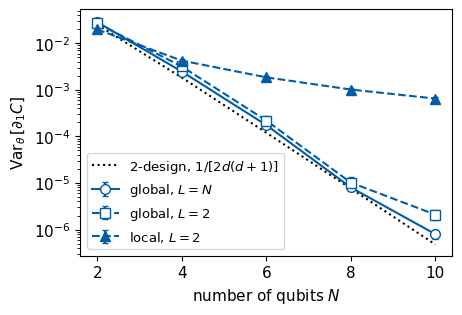

In [6]:
fig, ax = plt.subplots()
styles = {"HEA L=N, global": ("o", "-", COL["hea"], "white", r"global, $L=N$"),
          "HEA L=2, global": ("s", "--", COL["hea"], "white", r"global, $L=2$"),
          "HEA L=2, local": ("^", "--", COL["hea"], COL["hea"], r"local, $L=2$")}
for name, (m, ls, col, face, lab) in styles.items():
    v = np.array([r[0] for r in CURVES[name]]); e = np.array([r[1] for r in CURVES[name]])
    ax.errorbar(Ns, v, yerr=e, fmt=m + ls, color=col, mfc=face, ms=7, capsize=2, lw=1.5, label=lab)
ax.semilogy(Ns, haar_global, ":", color=COL["exact"], lw=1.5, label=r"2-design, $1/[2d(d+1)]$")
ax.set_yscale("log"); ax.set_xticks(Ns)
ax.set_xlabel(r"number of qubits $N$"); ax.set_ylabel(r"Var$_\theta\,[\partial_1 C]$")
ax.legend(loc="lower left", fontsize=9.5)
save(fig, "fig_lab071_global_local"); plt.show()
NUMBERS.update(FitGlobalDeep=f"{FITS['HEA L=N, global']:.2f}", FitGlobalShallow=f"{FITS['HEA L=2, global']:.2f}",
               FitLocalShallow=f"{FITS['HEA L=2, local']:.2f}", FitTwoDesignGlobal=f"{fit_exponent(haar_global):.2f}",
               VarGlobalDeepTen=sci(CURVES['HEA L=N, global'][-1][0]), VarLocalShallowTen=sci(CURVES['HEA L=2, local'][-1][0]),
               NsqVarLocal=f"{mean_n2:.3f}", RatioLocalGlobalTen=f"{CURVES['HEA L=2, local'][-1][0] / CURVES['HEA L=2, global'][-1][0]:.0f}")

The global cost decays exponentially at both depths. At $L=N$ the fitted exponent is close to two, the value of a 2-design, and the variance falls by more than four orders of magnitude between $N=2$ and $N=10$. A shallow circuit gives the global cost no protection, since at $L=2$ it decays at a similar rate. The global cost compares the whole bit string with $0\dots0$, and its value is the probability of a single bit string out of $2^N$, which is exponentially small for almost all angles, whatever the depth. This dependence on the cost was proved for layered circuits of local 2-designs in Ref. [5], and our HEA, which is not of that form, shows the same behaviour.

The local cost at $L=2$ decays slowly, and $N^2\,\mathrm{Var}$ is constant for $N\ge6$ within the statistical errors, as equation (7) predicts. At $N=10$ its gradient variance is several hundred times larger than that of the global cost of the same circuit. The derivative of a local cost at fixed depth sees only the qubits inside the light cone of the differentiated gate, and the number of these qubits does not grow with $N$. For local costs and depths growing as $\log N$ the variance decays at most polynomially [5], whereas circuits deep enough to form 2-designs bring back the exponential decay of equation (6) for local costs too.

## 6. The energy for the hardware-efficient and the Hamiltonian-variational circuits

The energy (1) is the cost of a variational eigensolver. We measure the variance of its derivative for the HEA at depth $L=N$, with respect to $\theta_1$, and for the HVA at depth $L=N$, with respect to $\gamma_1$, and compare with the 2-design value of equation (6), $\mathrm{Var}\approx[(N-1)J^2+Nh^2]/2^{N+1}$.

HEA L=N, energy: Var from 0.409 (N=2) to 0.16 (N=10), fitted c = 0.14
HVA L=N, energy: Var from 7.08 (N=2) to 51 (N=10), fitted c = -0.33
2-design: 0.4 to 0.00928, fitted c = 0.76


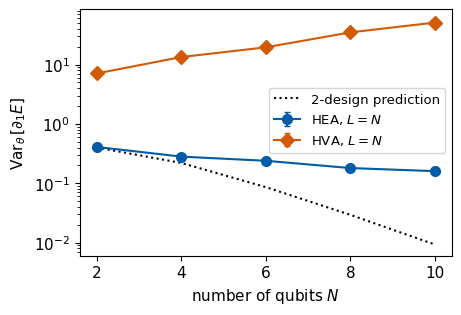

In [7]:
fig, ax = plt.subplots()
for name, (m, col, lab) in {"HEA L=N, energy": ("o", COL["hea"], r"HEA, $L=N$"), "HVA L=N, energy": ("D", COL["hva"], r"HVA, $L=N$")}.items():
    v = np.array([r[0] for r in CURVES[name]]); e = np.array([r[1] for r in CURVES[name]])
    ax.errorbar(Ns, v, yerr=e, fmt=m + "-", color=col, ms=7, capsize=2, lw=1.5, label=lab)
ax.semilogy(Ns, haar_energy, ":", color=COL["exact"], lw=1.5, label="2-design prediction")
ax.set_yscale("log"); ax.set_xticks(Ns)
ax.set_xlabel(r"number of qubits $N$"); ax.set_ylabel(r"Var$_\theta\,[\partial_1 E]$")
ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.55), fontsize=9.5)
save(fig, "fig_lab071_energy"); plt.show()
for name in ("HEA L=N, energy", "HVA L=N, energy"):
    print(f"{name}: Var from {CURVES[name][0][0]:.3g} (N=2) to {CURVES[name][-1][0]:.3g} (N=10), fitted c = {FITS[name]:.2f}")
print(f"2-design: {haar_energy[0]:.3g} to {haar_energy[-1]:.3g}, fitted c = {fit_exponent(haar_energy):.2f}")
assert FITS["HVA L=N, energy"] < 0 and CURVES["HEA L=N, energy"][-1][0] > 5 * haar_energy[-1]
NUMBERS.update(VarEnergyHEATwo=f"{CURVES['HEA L=N, energy'][0][0]:.2f}", VarEnergyHEATen=f"{CURVES['HEA L=N, energy'][-1][0]:.2f}",
               FitEnergyHEA=f"{FITS['HEA L=N, energy']:.2f}", VarEnergyHVATwo=f"{CURVES['HVA L=N, energy'][0][0]:.1f}",
               VarEnergyHVATen=f"{CURVES['HVA L=N, energy'][-1][0]:.0f}", VarEnergyTwoDesignTen=sci(haar_energy[-1]),
               FitEnergyTwoDesign=f"{fit_exponent(haar_energy):.2f}")

The 2-design curve falls by about a factor of two per qubit. The energy gradient of the HEA at depth $L=N$ decays far more slowly over these sizes and lies more than an order of magnitude above the 2-design value at $N=10$. The energy is a sum of terms on one or two neighbouring qubits, and each term is affected only by the gates inside its light cone. A $\widehat{\mathrm{CZ}}$ chain spreads information by one qubit per layer, so at depth $N$ the circuit has only just connected the two ends of the chain and is still far from a random unitary. These sizes cannot fix the asymptotic decay rate of the HEA, which approaches equation (6) once the circuit is deep enough to form a 2-design.

The variance of the HVA grows with $N$. Each of its angles multiplies a sum over all bonds or all qubits, so one angle changes all $2N-1$ terms of the energy together, and the derivative adds up contributions from the whole chain. The HVA also never approaches a random unitary. Its gates commute with the parity $\hat\Pi$ and, more restrictively, they generate only a small family of unitaries whose dimension grows polynomially with $N$, so the states it prepares fill a small part of the $2^N$-dimensional space. Mild or absent barren plateaus for this ansatz were reported in Ref. [4]. The size of the set of unitaries generated by the gates of a circuit, its dynamical Lie algebra, determines the gradient variance in general [6,7].

## 7. Shots needed to resolve a gradient

A device estimates a gradient component with the parameter-shift rule from two energies, each measured with $M$ shots per setting. When the angle $\theta_k$ enters a single gate, as in the HEA, the error propagation of the two estimates gives the statistical variance $\sigma^2/(2M)$ of the estimated component, where $\sigma^2=\sigma_Z^2+\sigma_X^2$ is the single-shot variance of the energy. The typical gradient becomes visible above the shot noise when this variance equals $\mathrm{Var}_{\boldsymbol\theta}[\partial_kE]$, which requires
$$M^\star=\frac{\sigma^2}{2\,\mathrm{Var}_{\boldsymbol\theta}[\partial_kE]} \tag{8}$$
shots per setting and per shifted circuit. In a random state $\sigma^2\approx\sum_jc_j^2=(N-1)J^2+Nh^2$, and with equation (6) for the variance the 2-design value is $M^\star\approx d-1=2^N-1$. Every added qubit then doubles the number of shots for one gradient component.

An angle of the HVA enters many gates. The angle $\gamma_1$ appears in the $N-1$ gates $\hat R_{zz}(\theta_g)$ of the first layer, each with $\theta_g=2\gamma_1$, so the chain rule gives $\partial E/\partial\gamma_1=\sum_g2\,\partial E/\partial\theta_g$. Each of the $N-1$ terms is measured with the two-point rule by shifting the angle of one gate alone, which takes $2(N-1)$ circuits. The terms are estimated independently, and their variances add with the squared factors $c_g^2=4$, so the variance of the estimated derivative is $4(N-1)\,\sigma^2/(2M)$. For an angle that enters gates with factors $c_g$, equation (8) becomes
$$M^\star=\frac{\sigma^2\sum_gc_g^2}{2\,\mathrm{Var}_{\boldsymbol\theta}[\partial_kE]} , \tag{9}$$
with $\sum_gc_g^2=4(N-1)$ for $\gamma_1$. The code first checks the chain rule for $\gamma_1$ at $N=6$ against `jax.grad`, with each gate shifted separately, and then evaluates equations (8) and (9) with the measured variances and the measured $\sigma^2$, averaged over the sampled states.

HVA, N = 6: chain rule over 5 gates (10 circuits) 1.827090, jax.grad 1.827090
           circuit       N=2       N=4       N=6       N=8      N=10   shots per setting and shifted circuit, equations (8) and (9)
   HEA L=N, energy       2.9      11.1      21.5      39.8      57.7
   HVA L=N, energy     0.899         3      5.33      5.89      6.72
      HVA circuits         2         6        10        14        18   shifted circuits per component of gamma_1
          2-design         3        15        63       255      1023
2-design, N = 20: M* = 2^N - 1 = 1.0e+06 shots
2-design, N = 50: M* = 2^N - 1 = 1.1e+15 shots
   HEA L=N, global      2.45      10.4      46.4       242       639
    HEA L=2, local      2.38      5.81      8.96      12.4      15.5


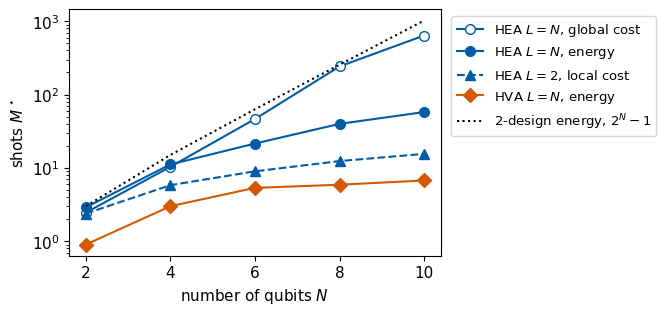

In [8]:
def hva_state_bond_shift(theta, N, L, bond, shift):
    # the HVA with the angle 2 gamma_1 of the single gate R_zz on (bond, bond + 1) shifted by `shift`
    z, zz, _ = tables(N)
    psi = jnp.ones((2,) * N, dtype=CDTYPE) / 2 ** (N / 2)
    for l, (gamma, beta) in enumerate(theta.reshape(L, 2)):
        psi = psi * jnp.exp(-1j * gamma * zz)
        if l == 0:
            psi = psi * jnp.exp(-1j * shift / 2 * z[bond] * z[bond + 1])     # extra R_zz(shift) on one bond
        psi = rotate_all(psi, jnp.broadcast_to(rotation(X, 2 * beta), (N, 2, 2)))
    return psi

N6 = 6
th6 = jax.random.uniform(jax.random.PRNGKey(7104), (2 * N6,), minval=-np.pi, maxval=np.pi)
E6 = lambda psi: energy_and_variance(psi)[0]
d_chain = sum(2 * (E6(hva_state_bond_shift(th6, N6, N6, b, np.pi / 2)) - E6(hva_state_bond_shift(th6, N6, N6, b, -np.pi / 2))) / 2
              for b in range(N6 - 1))
d_auto = jax.grad(lambda t: E6(hva_state(t, N6, N6)))(th6)[0]
assert abs(float(d_chain) - float(d_auto)) < 1e-12
assert abs(E6(hva_state_bond_shift(th6, N6, N6, 2, 0.0)) - E6(hva_state(th6, N6, N6))) < TOL
print(f"HVA, N = {N6}: chain rule over {N6 - 1} gates ({2 * (N6 - 1)} circuits) {float(d_chain):.6f}, jax.grad {float(d_auto):.6f}")

M_star = {}
print(f"{'circuit':>18s} " + " ".join(f"{'N=' + str(N):>9s}" for N in N_LIST) + "   shots per setting and shifted circuit, equations (8) and (9)")
sum_c2 = {"HEA L=N, energy": np.ones(len(N_LIST)), "HVA L=N, energy": 4.0 * (np.array(N_LIST) - 1)}
for name in ("HEA L=N, energy", "HVA L=N, energy"):
    M_star[name] = np.array(SIGMA2[name]) * sum_c2[name] / (2 * np.array([r[0] for r in CURVES[name]]))
    print(f"{name:>18s} " + " ".join(f"{m:9.3g}" for m in M_star[name]))
print(f"{'HVA circuits':>18s} " + " ".join(f"{2 * (N - 1):9d}" for N in N_LIST) + "   shifted circuits per component of gamma_1")
sigma2_haar = np.array([2.0 ** N / (2.0 ** N + 1) * ((N - 1) * J ** 2 + N * h ** 2) for N in N_LIST])
M_star["2-design"] = sigma2_haar / (2 * haar_energy)
print(f"{'2-design':>18s} " + " ".join(f"{m:9.0f}" for m in M_star["2-design"]))
assert np.allclose(M_star["2-design"], 2.0 ** np.array(N_LIST) - 1)
for N_far in (20, 50):
    print(f"2-design, N = {N_far}: M* = 2^N - 1 = {2.0 ** N_far - 1:.1e} shots")
NUMBERS.update(MstarHEATen=f"{M_star['HEA L=N, energy'][-1]:.0f}", MstarTwoDesignTen=f"{M_star['2-design'][-1]:.0f}",
               MstarHVATen=f"{M_star['HVA L=N, energy'][-1]:.1f}", HVACircuitsTen=f"{2 * (N_LIST[-1] - 1)}", MstarTwoDesignTwenty=sci(2.0 ** 20, 0),
               MstarTwoDesignFifty=sci(2.0 ** 50, 0))

# shots needed for the global and local costs of the HEA, equation (8) with their single-shot variances
for name in ("HEA L=N, global", "HEA L=2, local"):
    M_star[name] = np.array(SIGMA2[name]) / (2 * np.array([r[0] for r in CURVES[name]]))
    print(f"{name:>18s} " + " ".join(f"{m:9.3g}" for m in M_star[name]))
fig, ax = plt.subplots()
ax.semilogy(Ns, M_star["HEA L=N, global"], "o-", color=COL["hea"], mfc="white", ms=7, lw=1.5, label=r"HEA $L=N$, global cost")
ax.semilogy(Ns, M_star["HEA L=N, energy"], "o-", color=COL["hea"], ms=7, lw=1.5, label=r"HEA $L=N$, energy")
ax.semilogy(Ns, M_star["HEA L=2, local"], "^--", color=COL["hea"], ms=7, lw=1.5, label=r"HEA $L=2$, local cost")
ax.semilogy(Ns, M_star["HVA L=N, energy"], "D-", color=COL["hva"], ms=7, lw=1.5, label=r"HVA $L=N$, energy")
ax.semilogy(Ns, M_star["2-design"], ":", color=COL["exact"], lw=1.5, label=r"2-design energy, $2^N-1$")
ax.set_xticks(Ns); ax.set_xlabel(r"number of qubits $N$"); ax.set_ylabel(r"shots $M^\star$")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9.5)
save(fig, "fig_lab071_shots_needed"); plt.show()
NUMBERS.update(MstarGlobalTen=f"{M_star['HEA L=N, global'][-1]:.0f}", MstarLocalTen=f"{M_star['HEA L=2, local'][-1]:.2g}")

The figure collects $M^\star$ for all circuits and costs, with the single-shot variance of the global cost, $C_G(1-C_G)$, and of the local cost, the variance of the fraction of bits equal to 1, measured at the sampled states. The global cost of the deep HEA needs a number of shots that grows exponentially with $N$, whereas the local cost at $L=2$ and the HVA need few. At $N=10$ a typical energy gradient of the deep HEA is resolved with about sixty shots per setting, while a 2-design would need about a thousand. For the 2-design the count doubles with every qubit and reaches about $10^6$ shots at $N=20$ and $10^{15}$ at $N=50$, for a single component of a single gradient. The gradient of the HVA with respect to $\gamma_1$ is resolved with a few shots per setting in each of its $2(N-1)$ shifted circuits, about one shot at $N=2$ and seven at $N=10$. The growth is slow and set by the number of gates that share the angle. These numbers describe the start of training at uniformly random angles, where the optimiser must first find a direction downhill. A barren plateau cannot be removed by a better optimiser, because every optimiser on a device has to resolve the gradient, or differences of energies, above the shot noise, and equations (8) and (9) set the cost of doing so. The core route ends here.

## 8. Noise and ways around barren plateaus

Noise on a device produces a second kind of plateau. Depolarising noise after each layer replaces part of the state by the maximally mixed state, on which every traceless observable has expectation value zero. The whole cost landscape therefore contracts towards a constant by a factor that decays exponentially with the depth. For circuits whose depth grows linearly with $N$ the gradient then vanishes exponentially in $N$, independently of the random-unitary argument of Section 4 and also for structured ansätze [8]. The only remedy within the circuit is a smaller depth or lower error rates.

The known ways of keeping the gradient measurable change the cost, the circuit or the starting point.

- Local costs, built from terms that act on few qubits, decay at most polynomially for circuits of logarithmic depth [5], as Section 5 shows for the HEA at $L=2$.
- Shallow circuits keep the light cone of each gate small, and they also limit the effect of noise [5,8].
- Structured ansätze that respect the symmetries of the problem, such as the HVA, prepare states in a small part of the state space and keep large gradients, as Section 6 shows [4]. The dimension of the dynamical Lie algebra of the circuit predicts when this happens [6,7].
- Initial angles chosen so that the circuit starts as the identity [9], or circuits trained layer by layer [10], start training away from the random region.

All of these measures restrict the set of states that the circuit explores. A circuit that can prepare almost any state, a highly expressive ansatz, has small gradients, and expressibility and trainability have to be balanced [11].

## 9. Exercises

1. Show that the derivative $-b\sin(\theta_k-c)$ averages to zero over $\theta_k\in[-\pi,\pi]$, and check numerically that the mean gradient of Section 5 is zero within its standard error.
2. Derive $\mathrm{Var}\,\langle\hat Z_0\rangle=1/(d+1)$ for random states, starting from the fact that the vector of probabilities $|\psi_{\mathbf b}|^2$ of a random state is uniformly distributed on the probability simplex.
3. Measure the variance for the local cost of the HEA at depth $L=N$ and compare it with $L=2$ and with the 2-design value $2^{-N}/(8N)$.
4. Differentiate with respect to the last angle of the HEA instead of the first, and explain the result for the local cost at $L=2$ with the light-cone argument.
5. Draw the HEA angles uniformly from $[-\epsilon,\epsilon]$ with $\epsilon=0.1$ and measure the variance of the global cost against $N$.
6. Show that equations (6) and (8) give $M^\star=d-1$ for a 2-design, using $\sigma^2=d\sum_jc_j^2/(d+1)$ for a random state.
7. For the global cost a single shot is a yes-or-no outcome with variance $C_G(1-C_G)$. Estimate $M^\star$ for the global cost of the deep HEA at $N=10$.

## 10. Summary

For angles drawn at random, the mean of every gradient component vanishes and its variance measures the typical gradient. In a random state every expectation value concentrates around its mean, with a variance of order $2^{-N}$. A circuit that acts as a random unitary gives gradient variances that decay exponentially with $N$, at a rate set by the size of the cost observable. Global costs decay exponentially for the hardware-efficient circuit at every depth considered, with the 2-design exponent at depth $N$. A local cost at fixed depth keeps a gradient variance that decreases only as $1/N^2$, because the derivative sees only the qubits inside the light cone of the differentiated gate. The energy of the Ising chain decays slowly for the hardware-efficient circuit at the sizes studied. Its gradient grows with $N$ for the Hamiltonian-variational circuit, whose shared angles and symmetry keep it in a small part of the state space. The number of shots needed to resolve a gradient is the ratio of the single-shot variance to the gradient variance, and for a random unitary it doubles with every qubit.

## References

[1] J. R. McClean, S. Boixo, V. N. Smelyanskiy, R. Babbush and H. Neven, Barren plateaus in quantum neural network training landscapes, Nat. Commun. **9**, 4812 (2018), doi:[10.1038/s41467-018-07090-4](https://doi.org/10.1038/s41467-018-07090-4).

[2] A. Kandala, A. Mezzacapo, K. Temme, M. Takita, M. Brink, J. M. Chow and J. M. Gambetta, Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets, Nature **549**, 242 (2017), doi:[10.1038/nature23879](https://doi.org/10.1038/nature23879).

[3] D. Wecker, M. B. Hastings and M. Troyer, Progress towards practical quantum variational algorithms, Phys. Rev. A **92**, 042303 (2015), doi:[10.1103/PhysRevA.92.042303](https://doi.org/10.1103/PhysRevA.92.042303).

[4] R. Wiersema, C. Zhou, Y. de Sereville, J. F. Carrasquilla, Y. B. Kim and H. Yuen, Exploring entanglement and optimization within the Hamiltonian variational ansatz, PRX Quantum **1**, 020319 (2020), doi:[10.1103/PRXQuantum.1.020319](https://doi.org/10.1103/PRXQuantum.1.020319).

[5] M. Cerezo, A. Sone, T. Volkoff, L. Cincio and P. J. Coles, Cost function dependent barren plateaus in shallow parametrized quantum circuits, Nat. Commun. **12**, 1791 (2021), doi:[10.1038/s41467-021-21728-w](https://doi.org/10.1038/s41467-021-21728-w).

[6] M. Ragone, B. N. Bakalov, F. Sauvage, A. F. Kemper, C. Ortiz Marrero, M. Larocca and M. Cerezo, A Lie algebraic theory of barren plateaus for deep parameterized quantum circuits, Nat. Commun. **15**, 7172 (2024), doi:[10.1038/s41467-024-49909-3](https://doi.org/10.1038/s41467-024-49909-3).

[7] M. Larocca, S. Thanasilp, S. Wang, K. Sharma, J. Biamonte, P. J. Coles, L. Cincio, J. R. McClean, Z. Holmes and M. Cerezo, Barren plateaus in variational quantum computing, Nat. Rev. Phys. **7**, 174 (2025), doi:[10.1038/s42254-025-00813-9](https://doi.org/10.1038/s42254-025-00813-9).

[8] S. Wang, E. Fontana, M. Cerezo, K. Sharma, A. Sone, L. Cincio and P. J. Coles, Noise-induced barren plateaus in variational quantum algorithms, Nat. Commun. **12**, 6961 (2021), doi:[10.1038/s41467-021-27045-6](https://doi.org/10.1038/s41467-021-27045-6).

[9] E. Grant, L. Wossnig, M. Ostaszewski and M. Benedetti, An initialization strategy for addressing barren plateaus in parametrized quantum circuits, Quantum **3**, 214 (2019), doi:[10.22331/q--214](https://doi.org/10.22331/q--214).

[10] A. Skolik, J. R. McClean, M. Mohseni, P. van der Smagt and M. Leib, Layerwise learning for quantum neural networks, Quantum Mach. Intell. **3**, 5 (2021), doi:[10.1007/s42484-020-00036-4](https://doi.org/10.1007/s42484-020-00036-4).

[11] Z. Holmes, K. Sharma, M. Cerezo and P. J. Coles, Connecting ansatz expressibility to gradient magnitudes and barren plateaus, PRX Quantum **3**, 010313 (2022), doi:[10.1103/PRXQuantum.3.010313](https://doi.org/10.1103/PRXQuantum.3.010313).